# 04 — Network Topology, Stops & Metro Connections

**Goal:** characterise the spatial/network layer — where stops are, which are hubs, network
density per district, and which routes form the Metro Line 1 feeder set.

This feeds the *Network & Metro* and *Spatial Insights* themes in the operator dashboard
and the *"Routes near me"* / *"Peak footfall"* features on the passenger side.


In [1]:
import sys, os
sys.path.insert(0, os.path.abspath('..'))
import pandas as pd, numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import plotly.express as px
import plotly.graph_objects as go
from src.duckdb_loader import BusDuckDB

sns.set_theme(style='whitegrid', context='notebook')
db = BusDuckDB('../data', ':memory:')
db.register_views()
print('OK')


INFO | DuckDB ready


INFO | View 'tickets' registered (90 file(s))


INFO | View 'payments' registered (90 file(s))


INFO | View 'gps_raw' registered


INFO | View 'gps_trips' registered


INFO | View 'gps_stop_times' registered


... (16 outputs left out)

INFO | View 'ticket_schools' registered


INFO | View 'stops' registered


INFO | View 'mapping' registered


OK


## 1. Stop master — types and zones


In [2]:
types = db.query('''
    SELECT type, COUNT(*) AS n
    FROM stops
    GROUP BY type ORDER BY n DESC
''').to_pandas()
print('Stop types:'); print(types)

zones = db.query('''
    SELECT zone, COUNT(*) AS n
    FROM stops
    WHERE zone IS NOT NULL
    GROUP BY zone ORDER BY n DESC
    LIMIT 25
''').to_pandas()
fig = px.bar(zones.sort_values('n'), x='n', y='zone', orientation='h',
    color='n', color_continuous_scale='Blues',
    title='Stops per district / zone (top 25)',
    labels={'n':'Stops','zone':''})
fig.update_layout(coloraxis_showscale=False, height=600, margin=dict(l=200))
fig.show()


Stop types:
                  type     n
0             Trụ dừng  3099
1              Nhà chờ   760
2                Ô sơn   642
3               Bến xe   110
4            Biển treo    64
5             Trạm tạm    16
6        Ga Metro Số 1    14
7       Bến Bãi QH 568     3
8  Bến bãi QH chung QH     2


## 2. Hub stops — how many routes pass through each stop

`stops.routes` is a string with comma-separated route numbers. Parsing it gives us the
inverted index *stop → routes count*.


In [3]:
hubs = db.query('''
    SELECT stopId, stop_name, zone, lat, lng, routes,
           LIST_AGGREGATE(
               STRING_SPLIT(REGEXP_REPLACE(routes, '\s+', '', 'g'), ','),
               'count'
           ) AS route_count
    FROM stops
    WHERE routes IS NOT NULL
    ORDER BY route_count DESC
''').to_pandas()

print(f'Stops with route info: {len(hubs):,}')
print('\nTop 15 hubs:')
hubs[['stop_name','zone','route_count','routes']].head(15)


Stops with route info: 4,710

Top 15 hubs:


<>:4: SyntaxWarning: invalid escape sequence '\s'
<>:4: SyntaxWarning: invalid escape sequence '\s'
/tmp/ipykernel_29293/3220789976.py:4: SyntaxWarning: invalid escape sequence '\s'
  STRING_SPLIT(REGEXP_REPLACE(routes, '\s+', '', 'g'), ','),


,stop_name,zone,route_count,routes
0,Bến xe buýt Sài Gòn,Quận 1,28,"03, 04, 102, 109, 13, 140, 18, 19, 20, 27, 28,..."
1,Tôn Thất Tùng,Quận 1,23,"03, 04, 102, 109, 13, 140, 156V, 18, 19, 20, 2..."
2,Nguyễn Thị Nghĩa,Quận 1,23,"03, 04, 102, 109, 13, 140, 156V, 18, 19, 20, 2..."
3,Tôn Thất Tùng,Quận 1,21,"03, 04, 102, 109, 13, 140, 156D, 18, 19, 20, 3..."
4,Nguyễn Thị Nghĩa,Quận 1,21,"03, 04, 102, 109, 13, 140, 156D, 18, 19, 20, 3..."
5,Đại học Hutech,Quận Bình Thạnh,18,"06, 10, 104, 14, 150, 157D, 157V, 161, 19, 30,..."
6,Nam Kỳ Khởi Nghĩa,Quận 1,17,"01, 03, 04, 109, 152, 18, 19, 20, 31, 36, 45, ..."
7,Chợ Cũ,Quận 1,17,"01, 03, 04, 109, 152, 18, 19, 20, 31, 36, 45, ..."
8,Trường Emst Thalmann,Quận 1,17,"03, 04, 109, 13, 156V, 18, 19, 20, 28, 34, 36,..."
9,Nghĩa trang liệt sĩ TP.HCM,TP. Thủ Đức - KV2,17,"08, 10, 150, 164V, 166V, 19, 33, 53, 56, 60-1,..."


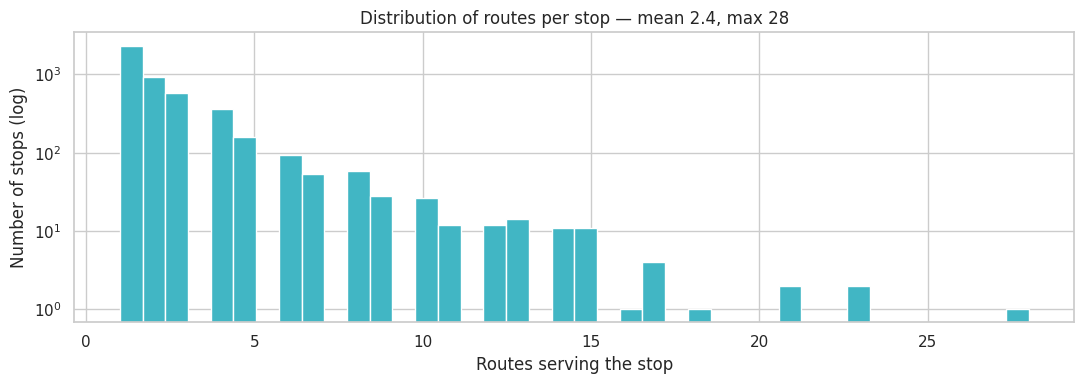

In [4]:
# Distribution of routes-per-stop
fig, ax = plt.subplots(figsize=(11,4))
ax.hist(hubs['route_count'].dropna(), bins=40, color='#41b6c4', edgecolor='white')
ax.set_yscale('log')
ax.set_xlabel('Routes serving the stop')
ax.set_ylabel('Number of stops (log)')
ax.set_title(f'Distribution of routes per stop — mean {hubs["route_count"].mean():.1f}, max {hubs["route_count"].max()}')
plt.tight_layout(); plt.show()


In [5]:
# Map of hubs — size by route count
fig = px.scatter_mapbox(
    hubs.dropna(subset=['lat','lng']).nlargest(100, 'route_count'),
    lat='lat', lon='lng', size='route_count', hover_name='stop_name',
    hover_data=['zone','route_count'],
    center=dict(lat=10.78, lon=106.69), zoom=10.3,
    mapbox_style='carto-positron', size_max=30,
    color='route_count', color_continuous_scale='Magma',
    title='Top 100 hub stops by route count',
)
fig.update_layout(height=620, margin=dict(l=0,r=0,t=40,b=0))
fig.show()


/tmp/ipykernel_29293/3623024898.py:2: DeprecationWarning: *scatter_mapbox* is deprecated! Use *scatter_map* instead. Learn more at: https://plotly.com/python/mapbox-to-maplibre/
  fig = px.scatter_mapbox(


## 3. Network density per district

A 500 m × 500 m or 1 km × 1 km grid (per `Bus system analytics_students.md`) gives a
"bus accessibility" map for the city — useful for both MCPT (where to add service) and
business owners (where to open up).


In [6]:
# Quick proxy: stop density by zone
density = db.query('''
    SELECT zone, COUNT(*) AS stops,
           AVG(lng) AS cx, AVG(lat) AS cy
    FROM stops
    WHERE zone IS NOT NULL AND lat IS NOT NULL AND lng IS NOT NULL
    GROUP BY zone
    HAVING stops >= 10
    ORDER BY stops DESC
''').to_pandas()

fig = px.scatter_mapbox(
    density, lat='cy', lon='cx', size='stops', hover_name='zone',
    color='stops', color_continuous_scale='Viridis',
    mapbox_style='carto-positron', center=dict(lat=10.78, lon=106.69), zoom=10,
    size_max=45,
    title='Stop density per district (size = stop count)',
)
fig.update_layout(height=620, margin=dict(l=0,r=0,t=40,b=0))
fig.show()


/tmp/ipykernel_29293/653813363.py:12: DeprecationWarning: *scatter_mapbox* is deprecated! Use *scatter_map* instead. Learn more at: https://plotly.com/python/mapbox-to-maplibre/
  fig = px.scatter_mapbox(


## 4. Metro Line 1 connection set

Per the HCMC dataset doc, 19 of the 31 selected routes connect to Metro Line 1. The full set
(per dataset paper Table 2) includes:

Route numbers connected: `70-5, 156D, 156V, 169D, 169V, 163D, 163V, 1, 164D, 164V, 167D, 167V,
152, 27, 148, 3, 45, 24, 50`

We map them and check coverage in our data.


In [7]:
metro_routes = ['70-5','156D','156V','169D','169V','163D','163V','1','164D','164V',
                 '167D','167V','152','27','148','3','45','24','50']
metro_str = ', '.join(repr(r) for r in metro_routes)

# Which of these are in our route master?
present = db.query(f'''
    SELECT route_no, route_name, distance, headway, total_trip, time_of_trip
    FROM gps_routes WHERE route_no IN ({metro_str})
    ORDER BY route_no
''').to_pandas()
print(f'{len(present)} of {len(metro_routes)} Metro-feeder routes present in gps_routes')
present


20 of 19 Metro-feeder routes present in gps_routes


,route_no,route_name,distance,headway,total_trip,time_of_trip
0,148,Bến xe Miền Tây - Gò Vấp,16700.0,12 - 18,128 [TPD],50 - 65
1,148,Bến xe Miền Tây - Gò Vấp,16700.0,12 - 18,128 [TPD],50 - 65
2,148,Bến xe Miền Tây - Gò Vấp,16700.0,12 - 18,128 [TPD],50 - 65
3,152,Khu dân cư Trung Sơn - Bến Thành - Sân bay T...,14550.0,12 - 18,120 [TPD],50 - 55
4,156D,Ga Bến Thành - Ga Hòa Hưng - Bệnh viện Mắt TP.HCM,7350.0,15 - 20,57 [TPD],30
5,156V,Ga Bến Thành - Đại học Sài Gòn Cơ sở 3 - Ga Hò...,7350.0,15 - 20,57 [TPD],30
6,163D,Ga Bình Thái - Trường Trung học cơ sở Phước Bì...,8000.0,10 - 15,79 [TPD],25
7,163V,Ga Bình Thái - Cao đẳng Công Thương - Trường T...,8000.0,10 - 15,79 [TPD],25
8,164D,Đại học Nông Lâm - Ga Metro Khu Công nghệ cao ...,10400.0,10 - 15,79 [TPD],35
9,164V,Đại học Nông Lâm - Chung cư Topaz - Ga Metro K...,10400.0,10 - 15,79 [TPD],35


In [8]:
# Boardings on metro-feeder routes (AFC side)
metro_demand = db.query(f'''
    SELECT r.route_no,
           COUNT(*) AS boardings,
           SUM(CASE WHEN t.ticket_type LIKE '%HS-SV%' THEN 1 ELSE 0 END) AS student_boardings
    FROM tickets t
    JOIN ticket_trips tt USING (trip_id)
    JOIN ticket_routes r USING (route_id)
    WHERE r.route_no IN ({metro_str})
    GROUP BY r.route_no
    ORDER BY boardings DESC
''').to_pandas()
metro_demand['student_share'] = metro_demand['student_boardings'] / metro_demand['boardings']
print(f'Metro-feeder routes with AFC data: {len(metro_demand)}')

fig = px.bar(
    metro_demand.sort_values('boardings'),
    x='boardings', y='route_no', orientation='h',
    color='student_share', color_continuous_scale='Plasma',
    title='Metro-feeder routes — boardings + student share',
    labels={'boardings':'Boardings (Jan–Mar 2026)','route_no':'Route','student_share':'Student %'},
)
fig.update_layout(height=520)
fig.show()


Metro-feeder routes with AFC data: 17


## 5. Stop → routes inverted index (interactive lookup demo)

A core utility for several features: *"which routes serve this stop?"* and *"which stops are
shared between routes A and B?"* (transfer-point detection).


In [9]:
# Build inverted index: route → list of stops
route_stops = db.query('''
    SELECT r.route_no, rs.route_id, rs.direction, rs.stop_order, rs.station_id,
           s.station_name, s.lat, s.lng
    FROM ticket_route_stops rs
    JOIN ticket_routes r USING (route_id)
    JOIN ticket_stations s USING (station_id)
    ORDER BY r.route_no, rs.direction, rs.stop_order
''').to_pandas()
print(f'Total route-stop edges: {len(route_stops):,}')
print(f'Routes with stop sequences: {route_stops["route_no"].nunique()}')

# Average stops per route per direction
spr = route_stops.groupby(['route_no','direction']).size().reset_index(name='stops')
print(f'\nMedian stops per route direction: {spr["stops"].median():.0f}')
print(f'Max stops in a single direction: {spr["stops"].max()}')


Total route-stop edges: 6,619
Routes with stop sequences: 61

Median stops per route direction: 50
Max stops in a single direction: 134


In [10]:
# Transfer hubs — stops where many routes converge
# Use the parsed routes from `stops` table for full network coverage
xfer = hubs.nlargest(20, 'route_count')[['stop_name','zone','route_count','routes']]
xfer


,stop_name,zone,route_count,routes
0,Bến xe buýt Sài Gòn,Quận 1,28,"03, 04, 102, 109, 13, 140, 18, 19, 20, 27, 28,..."
1,Tôn Thất Tùng,Quận 1,23,"03, 04, 102, 109, 13, 140, 156V, 18, 19, 20, 2..."
2,Nguyễn Thị Nghĩa,Quận 1,23,"03, 04, 102, 109, 13, 140, 156V, 18, 19, 20, 2..."
3,Tôn Thất Tùng,Quận 1,21,"03, 04, 102, 109, 13, 140, 156D, 18, 19, 20, 3..."
4,Nguyễn Thị Nghĩa,Quận 1,21,"03, 04, 102, 109, 13, 140, 156D, 18, 19, 20, 3..."
5,Đại học Hutech,Quận Bình Thạnh,18,"06, 10, 104, 14, 150, 157D, 157V, 161, 19, 30,..."
6,Nam Kỳ Khởi Nghĩa,Quận 1,17,"01, 03, 04, 109, 152, 18, 19, 20, 31, 36, 45, ..."
7,Chợ Cũ,Quận 1,17,"01, 03, 04, 109, 152, 18, 19, 20, 31, 36, 45, ..."
8,Trường Emst Thalmann,Quận 1,17,"03, 04, 109, 13, 156V, 18, 19, 20, 28, 34, 36,..."
9,Nghĩa trang liệt sĩ TP.HCM,TP. Thủ Đức - KV2,17,"08, 10, 150, 164V, 166V, 19, 33, 53, 56, 60-1,..."


## Takeaways — Network feasibility

| Feature | Evidence | Feasibility |
|---|---|---|
| Routes-near-me / hub lookup | `stops.routes` field, parsed | ✅ |
| District-level density map | zone + lat/lng per stop | ✅ |
| Metro-feeder demand audit | 19-route list × AFC boardings | ✅ (limited to AFC window) |
| Transfer-time simulation | needs schedule × GPS timing across years | ⚠️ aggregate proxy only |
| Network resilience (drop-a-route) | route → stops graph from `ticket_route_stops` | ✅ |
| Ghost-stop detection | needs `door_open` events × stop locations | ⚠️ 1-day GPS limits coverage |
| School-proximity scoring | needs geocoded school addresses | ⚠️ requires geocoding step (add to backlog) |
